In [2]:
# Task -- Feature Enggineering

# Extract aditional features from the existing columns, such as the length of the retaurant name or address.
# create new features like "Has Booking Table" or "Has Online Delivery" by encoding categorical variable.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("/home/vansh-kumar/cognifyz Task/Dataset .csv")
# data

print("\nOriginal dataset Shape:", data.shape)

data_new = data.copy()

# Restaurant Name Length

if "Restaurant Name" in data_new.columns:
    data_new["Restaurant_Name_Length"] = (data_new["Restaurant Name"].fillna("").astype(str).str.len())
    
    print("\nRestaurant name length created.")
else:
    print("\nRestaurant Name column not found.")
    


Original dataset Shape: (9551, 21)

Restaurant name length created.


In [4]:
# Address Length

if "Address" in data_new.columns:
    data_new["Address_Length"] = (data_new["Address"].fillna("").astype(str).str.len())
    
    print("Address length created.")
else:
    print("Address column not found.")

Address length created.


In [5]:
# Number of Cuisines

if "Cuisines" in data_new.columns:
    def count_cuisine(value):
        if pd.isna(value) or not str(value).strip():
            return 0 
        return len([cuisine.strip() for cuisine in str(value).strip(",") if cuisine.strip()])
    data_new["Number_of_Cuisines"] = (data_new["Cuisines"].apply(count_cuisine))
    print("Number of cuisines created.")

Number of cuisines created.


In [6]:
# Online Delivery Feature

if "Has Online Delivery" in data_new.columns:
    
    delivery = (data_new["Has Online delivery"].astype("string").str.strip().str.lower())
    data_new["Online_Delivery_Available"] = delivery.map({"yes":1,
                                                          "no":0})
    
    print("Online delivery feature created.")

In [7]:
# Table booking feature

if "Has Table booking" in data_new.columns:
    booking = (data_new["Has Table booking"].astype("string").str.strip().str.lower())
    
    data_new["Table_Booking_Available"] = booking.map({"yes":1,
                                                       "no":0})
    
    print("Table booking feature created.")

Table booking feature created.


In [8]:
# Raing category

if "Aggregate rating" in data_new.columns:
    rating = pd.to_numeric(data_new["Aggregate rating"], errors="coerce")
    
    data_new["Rating_Category"] = pd.cut(rating.where(rating > 0), bins= [0,2,3,4,5],labels=["Low", 
                                                                                             "Average",
                                                                                             "Good",
                                                                                             "Excellent"],include_lowest=True).cat.add_categories("Not Rated").fillna("Not Rated")
    
    print("Rating category created.")
    

Rating category created.


In [9]:
# Display new feature 

new_features = ["Restaurant_Name_Length",
                "Address_Length",
                "Number_of_Cuisines",
                "Online_Delivery_Available",
                "Table_Booking_Available",
                "Rating_Category"]

available_feature = [col for col in new_features if col in data_new.columns]

print("\nNew feature preview:")
print(data_new[available_feature].head(10).to_string(index=False))

print("\nNew Feature Summary:")
print(data_new[available_feature].describe(include="all").to_string())


New feature preview:
 Restaurant_Name_Length  Address_Length  Number_of_Cuisines  Table_Booking_Available Rating_Category
                     16              71                  24                        1       Excellent
                     16              67                   8                        1       Excellent
                     22              56                  29                        1       Excellent
                      4              70                  14                        0       Excellent
                     11              64                  15                        1       Excellent
                     12              71                   7                        0       Excellent
                     10              83                  14                        1            Good
                      7              81                  31                        1       Excellent
                     40              69                  21          

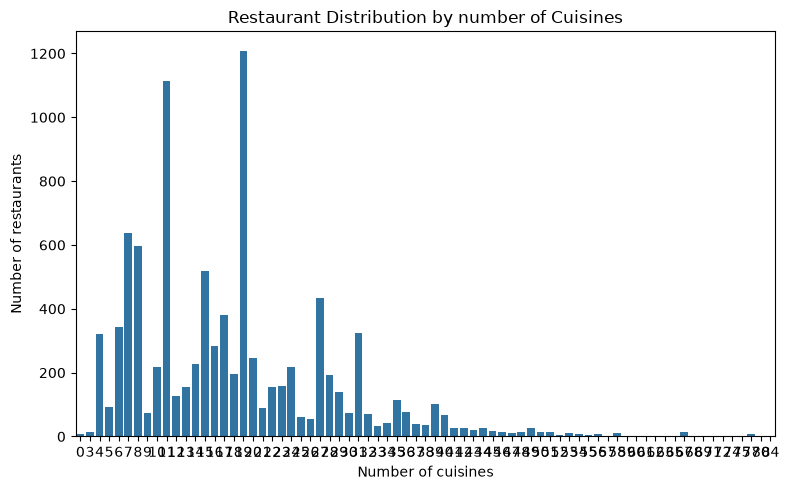

In [10]:
# Visualize number of Cuisines

if "Number_of_Cuisines"in data_new.columns:
    cuisine_counts = (data_new["Number_of_Cuisines"].value_counts().sort_index())
    
    plt.figure(figsize=(8,5))
    
    sns.barplot(x = cuisine_counts.index.astype(str), y= cuisine_counts.values) 
    plt.title("Restaurant Distribution by number of Cuisines")
    plt.xlabel("Number of cuisines")
    plt.ylabel("Number of restaurants")
    plt.tight_layout()
    plt.show()

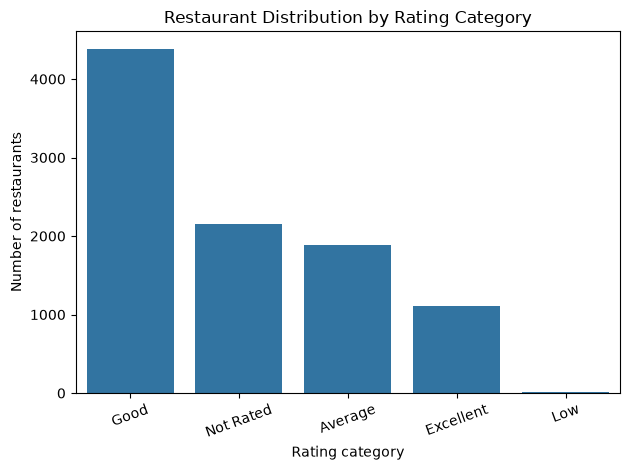

In [11]:
# visualize rating categories

if "Rating_Category" in data_new.columns:
    
    rating_counts = data_new["Rating_Category"].value_counts()
    plt.Figure(figsize=(9,5))
    sns.barplot(x= rating_counts.index.astype(str), y= rating_counts.values)
    
    plt.title("Restaurant Distribution by Rating Category")
    plt.xlabel("Rating category")
    plt.ylabel("Number of restaurants")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
    